# ✍️ Lesson 07 · Project 1 · Handwritten Digit Recognition

*“A project is where a pile of ideas becomes a skill. Today you ship a real classifier, and then you try to break it.”*

| ⏱ Time | 🎚 Level | 🗓 Suggested day | 📚 You should know |
|:--|:--|:--|:--|
| ~150 min | 🟡 Intermediate | Day 6 | Lessons 00–06 |

## 🎯 Learning objectives
By the end of this lesson you will be able to:

- Run a **complete, disciplined ML project**: frame → explore → split → baseline → train → evaluate → analyse errors
- Respect the **train / validation / test** split (and know why the test set is sacred)
- Train an ANN on real **MNIST** handwriting and reach ≥ 96 % accuracy
- Read a **confusion matrix**, per-class precision/recall, and **confidence** to understand *how* the model fails
- Discover the **limits of fully-connected networks** (the shift test): the motivation for CNNs
- Run the model on **your own handwriting**

## 🗺 Roadmap
1. Project brief
2. Look at the data
3. Split it honestly
4. Baselines
5. Train the ANN
6. Final test evaluation
7. Error analysis
8. Confidence & the reject option
9. Robustness: break it!
10. Your own handwriting
11. Keras version (preview)
12. Project report
13. Problems

## ⚙️ Setup
Run this cell first. It loads our libraries and the course helper module (`utils/dlcourse.py`).

In [1]:
import sys; sys.path.append("..")          # so we can import the course helper library
import numpy as np
import matplotlib.pyplot as plt
from utils import dlcourse as dl
import torch, torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader
dl.set_seed(42)                          # reproducible randomness
%matplotlib inline

---
## 📋 1. Project brief

> **Client.** A cooperative's farm-records office digitises hand-filled forms. Numbers written by hand (yields, quantities, plot IDs) must be read automatically.
> **Your job.** Build a model that reads a single handwritten digit (0–9) from a 28×28 image.

| | |
|:--|:--|
| **Data** | MNIST: 28×28 grayscale digits written by US census workers and students (we ship 20,000 train + 5,000 test) |
| **Model** | A fully-connected ANN in PyTorch |
| **Success criteria** | ≥ **96 %** test accuracy · you can explain *which* digits are confused and why · you've tested robustness |
| **Deliverable** | This notebook + the report table at the end |
| **Time** | ~2.5 hours |

**The workflow every ML project follows** (tape this above your desk):
`Frame the problem → Explore data → Split → Baseline → Model → Evaluate → Analyse errors → Iterate → Report`

---
## 🔭 2. Look at the data *first*

train pool: (20000, 28, 28) | test: (5000, 28, 28) | pixel range: 0.0 to 1.0


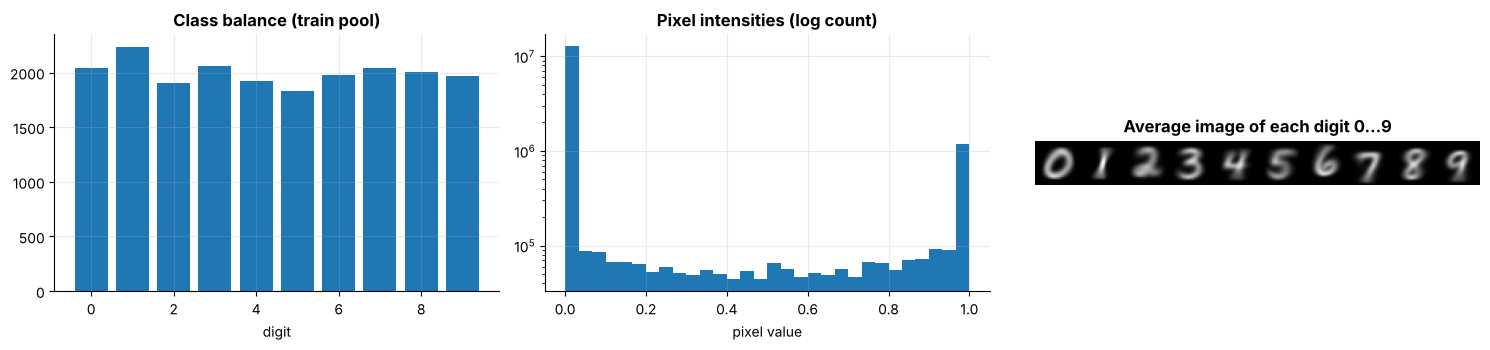

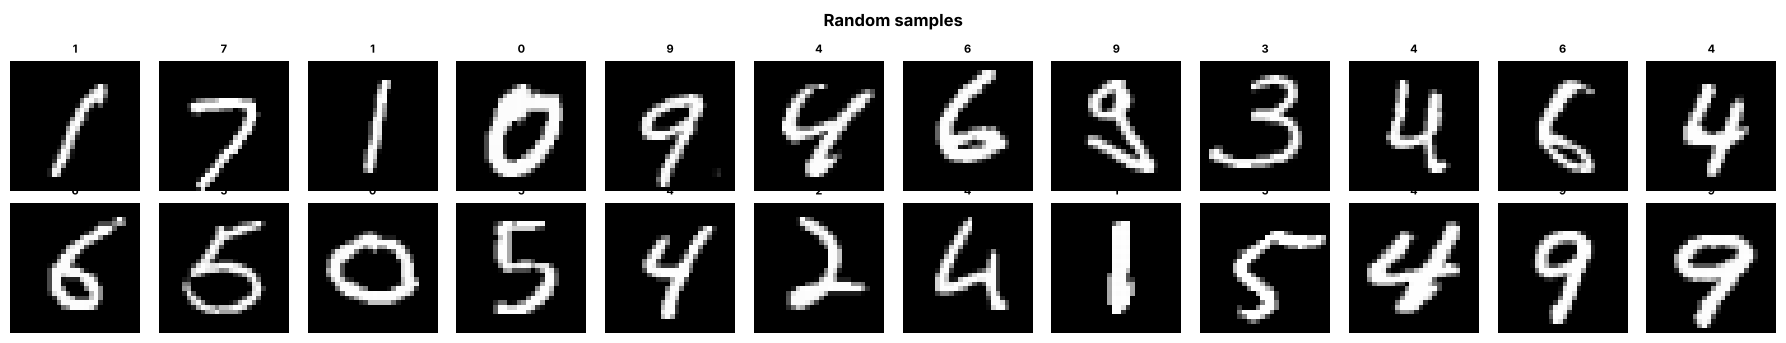

In [2]:
x_all, y_all, x_test, y_test = dl.load_mnist()                     # images are (N, 28, 28), floats in [0, 1]
print("train pool:", x_all.shape, "| test:", x_test.shape, "| pixel range:", x_all.min(), "to", x_all.max())

fig, ax = plt.subplots(1, 3, figsize=(15, 3.6))
ax[0].bar(range(10), np.bincount(y_all)); ax[0].set(title="Class balance (train pool)", xlabel="digit")
ax[1].hist(x_all.ravel(), bins=30, log=True); ax[1].set(title="Pixel intensities (log count)", xlabel="pixel value")
ax[2].imshow(np.hstack([x_all[y_all == d].mean(0) for d in range(10)]), cmap="gray"); ax[2].set(title="Average image of each digit 0…9"); ax[2].grid(False); ax[2].axis("off")
plt.tight_layout(); plt.show()
dl.show_images(x_all[:24], y_all[:24], n=24, ncols=12, title="Random samples")

**Observations to write down** (an engineer's notebook): classes are roughly balanced (so accuracy is a fair metric); ~80 % of pixels are exactly 0 (black background); the *average* images are blurry but recognisable: strong signal that pixels carry the information.

🤔 **Pause and think.** The average '1' is a thin vertical smear and the average '0' is a ring. What does that suggest about which digits will be hardest to tell apart?

<details><summary>Click to reveal the answer</summary>

Digits whose *average images overlap a lot*: e.g. **4 vs 9**, **3 vs 5 vs 8**, **7 vs 9**: will be confused most. We'll check this against the confusion matrix in Section 7.

</details>

---
## ✂️ 3. Split it honestly

| Set | Purpose | Rule |
|:--|:--|:--|
| **Train** | Learn weights | The model sees these |
| **Validation** | Choose hyper-parameters, stop training, compare models | Look at it *as often as you like* |
| **Test** | One final, honest estimate of real-world performance | **Look at it ONCE, at the very end** |

If you tune against the test set, you quietly overfit to it and your reported accuracy becomes optimistic. We carve a validation set out of the training pool and *don't touch* the test images until Section 6.

In [3]:
rng = np.random.default_rng(0)
perm = rng.permutation(len(y_all))
val_idx, tr_idx = perm[:4000], perm[4000:]
x_tr, y_tr, x_val, y_val = x_all[tr_idx], y_all[tr_idx], x_all[val_idx], y_all[val_idx]
print(f"train {len(y_tr):,} | validation {len(y_val):,} | test {len(y_test):,}  (test stays locked away 🔒)")

# Normalise with statistics from the TRAINING set only (using val/test statistics would be "leakage")
mu, sd = x_tr.mean(), x_tr.std()
prep = lambda a: torch.tensor((a - mu) / sd, dtype=torch.float32)
Xtr, Xval, Xte = prep(x_tr), prep(x_val), prep(x_test)
Ytr, Yval, Yte = (torch.tensor(a) for a in (y_tr, y_val, y_test))
train_dl = DataLoader(TensorDataset(Xtr, Ytr), batch_size=128, shuffle=True)
val_dl = DataLoader(TensorDataset(Xval, Yval), batch_size=1000)
print(f"normalisation: mean={mu:.4f}, std={sd:.4f}")

train 16,000 | validation 4,000 | test 5,000  (test stays locked away 🔒)
normalisation: mean=0.1307, std=0.3081


> ⚠️ **Watch out**: **Data leakage** = information from validation/test sneaking into training. Computing normalisation statistics on the whole dataset is a *mild* leak; selecting features or tuning on the test set is a severe one. Leakage produces gorgeous numbers that evaporate in production.

---
## 📏 4. Baselines: know what 'good' means

A model's accuracy means nothing without something to compare it to. Two baselines: guess the most common class, and a classical **logistic regression** (a single layer; no hidden layers!).

In [4]:
import warnings; warnings.filterwarnings("ignore")           # (sklearn may grumble about convergence; fine for a baseline)
from sklearn.linear_model import LogisticRegression
majority = np.bincount(y_tr).argmax()
print(f"majority-class baseline   : {np.mean(y_val == majority):.1%}")
logreg = LogisticRegression(max_iter=60)
logreg.fit(x_tr.reshape(len(x_tr), -1), y_tr)
print(f"logistic regression       : {logreg.score(x_val.reshape(len(x_val), -1), y_val):.1%}   ← a linear model, no hidden layers")

majority-class baseline   : 11.1%


logistic regression       : 92.0%   ← a linear model, no hidden layers


---
## 🧠 5. Train the ANN

Sequential(
  (0): Flatten(start_dim=1, end_dim=-1)
  (1): Linear(in_features=784, out_features=256, bias=True)
  (2): ReLU()
  (3): Linear(in_features=256, out_features=128, bias=True)
  (4): ReLU()
  (5): Linear(in_features=128, out_features=10, bias=True)
) 
parameters: 235,146


epoch   1/12 | train loss 0.5129 | val loss 0.2567 | train acc 0.852 | val acc 0.921


epoch   2/12 | train loss 0.2184 | val loss 0.1703 | train acc 0.935 | val acc 0.949


epoch   3/12 | train loss 0.1502 | val loss 0.1562 | train acc 0.954 | val acc 0.949


epoch   4/12 | train loss 0.1142 | val loss 0.1344 | train acc 0.963 | val acc 0.960


epoch   5/12 | train loss 0.0772 | val loss 0.1182 | train acc 0.977 | val acc 0.967


... (3 outputs left out)

epoch   9/12 | train loss 0.0209 | val loss 0.1248 | train acc 0.994 | val acc 0.963


epoch  10/12 | train loss 0.0183 | val loss 0.1110 | train acc 0.995 | val acc 0.972


epoch  11/12 | train loss 0.0114 | val loss 0.1107 | train acc 0.998 | val acc 0.971


epoch  12/12 | train loss 0.0068 | val loss 0.1173 | train acc 0.999 | val acc 0.971
done in 5.8s


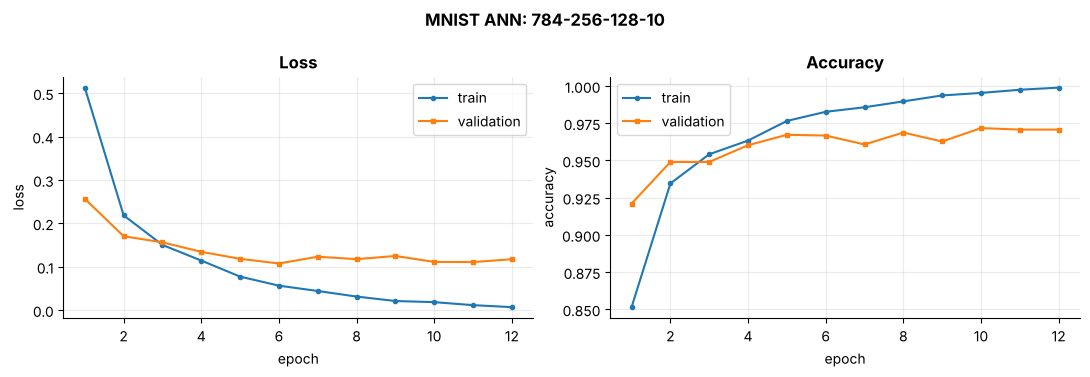

In [5]:
dl.set_seed(0)
model = nn.Sequential(
    nn.Flatten(),                       # (N,28,28) → (N,784)
    nn.Linear(784, 256), nn.ReLU(),
    nn.Linear(256, 128), nn.ReLU(),
    nn.Linear(128, 10),                 # 10 logits
)
print(model, "\nparameters:", f"{dl.count_params(model):,}")

cpu = torch.device("cpu")
history = dl.fit(model, train_dl, val_dl, nn.CrossEntropyLoss(), torch.optim.Adam(model.parameters(), lr=1e-3), epochs=12, device=cpu)
dl.plot_history(history, "MNIST ANN: 784-256-128-10")

**Read the curves.** Training loss falls steadily. Validation accuracy should climb to ~97 %. If the validation loss starts *rising* while training loss keeps falling, you are beginning to overfit: a sign to stop (or regularise).
Our initial loss was ≈ 2.3 = ln 10 (the Lesson 03 sanity check ✅).

---
## 🏁 6. The final exam: evaluate on the test set: once

🎯 TEST ACCURACY: 96.82%   (validation accuracy was 97.08%)


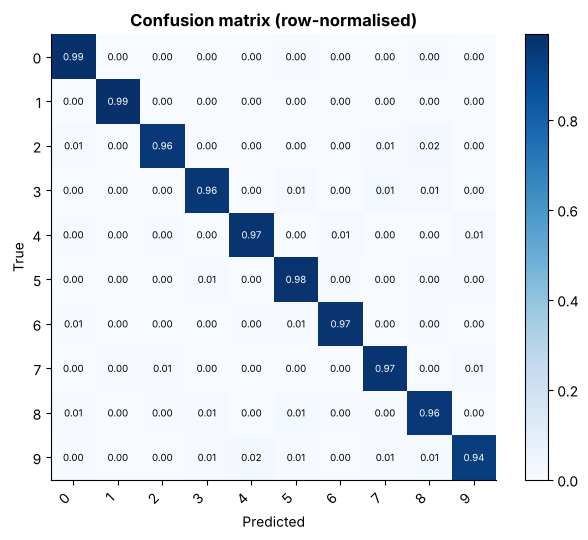

In [6]:
probs = dl.predict_proba(model, Xte, device=cpu)                 # (5000, 10) probabilities
preds = probs.argmax(1).numpy()
test_acc = (preds == y_test).mean()
print(f"🎯 TEST ACCURACY: {test_acc:.2%}   (validation accuracy was {history['val_acc'][-1]:.2%})")
cm = dl.plot_confusion(y_test, preds, class_names=list(range(10)), normalize=True, figsize=(6.5, 5.5))

In [7]:
from sklearn.metrics import classification_report
print(classification_report(y_test, preds, digits=3))

              precision    recall  f1-score   support

           0      0.961     0.985     0.973       470
           1      0.991     0.989     0.990       571
           2      0.976     0.958     0.967       520
           3      0.965     0.961     0.963       487
           4      0.972     0.972     0.972       505
           5      0.955     0.977     0.966       475
           6      0.975     0.973     0.974       483
           7      0.966     0.972     0.969       499
           8      0.942     0.955     0.948       490
           9      0.975     0.938     0.956       500

    accuracy                          0.968      5000
   macro avg      0.968     0.968     0.968      5000
weighted avg      0.968     0.968     0.968      5000



* **Precision** for class *c*: of the images the model *called* *c*, what fraction really were? ("When it says 7, can I trust it?")
* **Recall** for class *c*: of all the true *c* images, what fraction did it find? ("Does it miss any 7s?")
* **F1**: their harmonic mean: one number balancing both.

---
## 🔬 7. Error analysis: where and why does it fail?

  true 9 → predicted 4: 10 times
  true 2 → predicted 8: 9 times
  true 9 → predicted 8: 7 times
  true 3 → predicted 7: 7 times
  true 8 → predicted 5: 6 times
  true 2 → predicted 0: 6 times

159 mistakes out of 5000. Here are 24 of them (true→predicted):


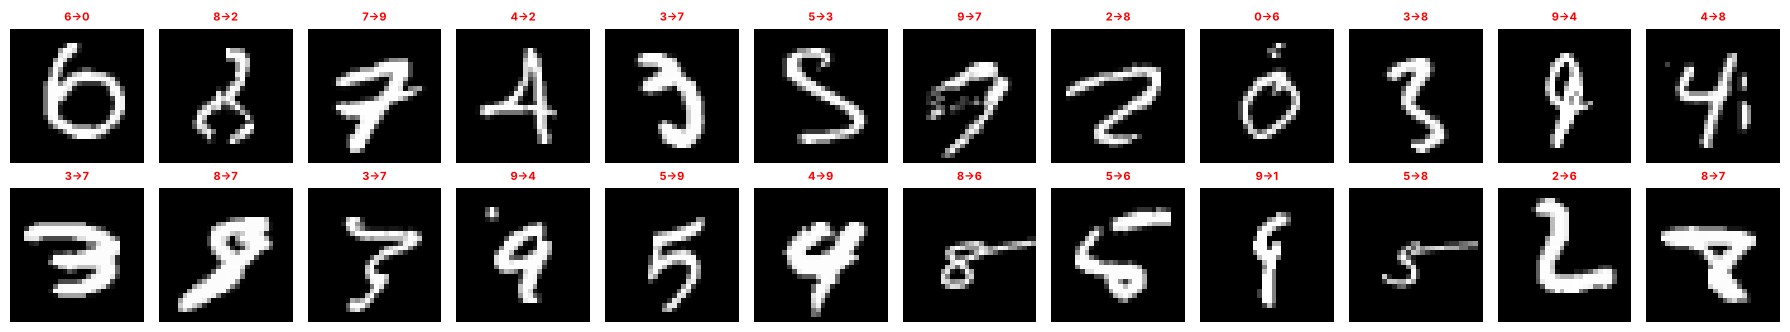

In [8]:
# Which pairs are confused most? (look at the off-diagonal counts)
from sklearn.metrics import confusion_matrix
raw = confusion_matrix(y_test, preds); off = raw.copy(); np.fill_diagonal(off, 0)
pairs = sorted([(off[i, j], i, j) for i in range(10) for j in range(10) if i != j], reverse=True)[:6]
for n, true, pred in pairs: print(f"  true {true} → predicted {pred}: {n} times")

wrong = np.where(preds != y_test)[0]
print(f"\n{len(wrong)} mistakes out of {len(y_test)}. Here are 24 of them (true→predicted):")
dl.show_images(x_test[wrong[:24]], y_test[wrong[:24]], preds=preds[wrong[:24]], n=24, ncols=12)

Look at those red images with a *human* eye. Some are honestly ambiguous (a sloppy 4 that looks like a 9; even people disagree). Others are clean digits the model simply got wrong. **This is the most valuable 10 minutes of any project**: it tells you whether more data, a better model, or a cleaner label set is what you need.

Now look at the model's **confidence** on its mistakes:

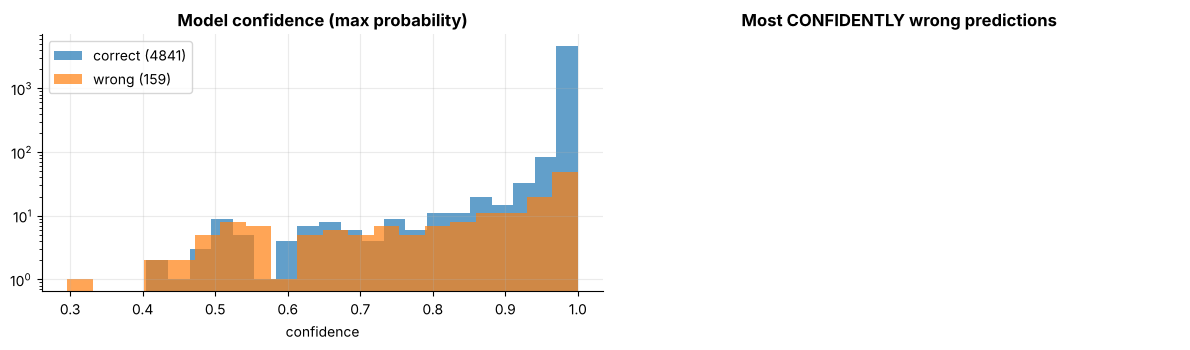

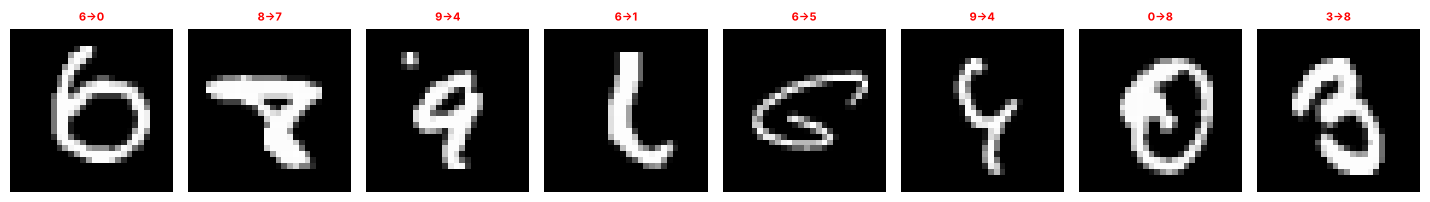

confidence of those: [1. 1. 1. 1. 1. 1. 1. 1.]


In [9]:
conf = probs.max(1).values.numpy()
correct = preds == y_test
fig, ax = plt.subplots(1, 2, figsize=(12, 3.6))
ax[0].hist(conf[correct], bins=20, alpha=.7, label=f"correct ({correct.sum()})", log=True)
ax[0].hist(conf[~correct], bins=20, alpha=.7, label=f"wrong ({(~correct).sum()})", log=True)
ax[0].set(title="Model confidence (max probability)", xlabel="confidence"); ax[0].legend()

sure_wrong = wrong[np.argsort(-conf[wrong])[:8]]
ax[1].axis("off"); ax[1].set_title("Most CONFIDENTLY wrong predictions")
plt.tight_layout(); plt.show()
dl.show_images(x_test[sure_wrong], y_test[sure_wrong], preds=preds[sure_wrong], n=8, ncols=8, figscale=1.8)
print("confidence of those:", conf[sure_wrong].round(3))

> 💡 **Big idea**: Correct predictions pile up near confidence 1.0; mistakes spread out. That's useful: **low confidence is a warning light.** We can exploit it with a *reject option*.

---
## 🚦 8. The reject option: knowing when to ask a human

A deployed system can say **"I'm not sure: send this to a person."** If the max probability is below a threshold, abstain. The trade-off: **coverage** (fraction of images the machine handles automatically) vs **accuracy on those it handles**.

In [10]:
for t in [0.0, 0.5, 0.8, 0.9, 0.99, 0.999]:
    keep = conf >= t
    print(f"threshold {t:5.3f} → handles {keep.mean():6.1%} automatically, accuracy on those: {correct[keep].mean():.2%}")

threshold 0.000 → handles 100.0% automatically, accuracy on those: 96.82%
threshold 0.500 → handles  99.7% automatically, accuracy on those: 96.99%
threshold 0.800 → handles  97.5% automatically, accuracy on those: 97.91%
threshold 0.900 → handles  96.2% automatically, accuracy on those: 98.38%
threshold 0.990 → handles  90.3% automatically, accuracy on those: 99.38%
threshold 0.999 → handles  81.6% automatically, accuracy on those: 99.73%


> 🇰🇪 **In the field**: For the records office: at threshold 0.99 the model handles most forms automatically and almost never errs; the rest go to a clerk. That is how real digitisation pipelines combine AI and people: *human-in-the-loop*.

---
## 💥 9. Robustness: let's try to break it

MNIST digits are neatly **centred**. What if a scanned digit sits slightly off-centre: a few pixels left or right? A human wouldn't care. Let's shift every test image horizontally by *d* pixels (filling with black) and re-measure accuracy.

accuracy vs horizontal shift: {0: 0.968, 1: 0.941, 2: 0.763, 3: 0.506, 4: 0.285, 5: 0.149}


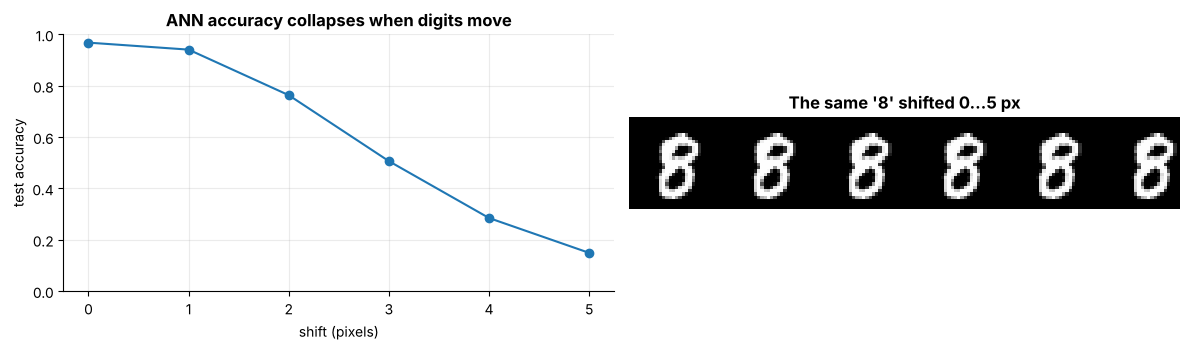

In [11]:
def shift_images(x, dx=0, dy=0):
    """Translate images by (dx, dy) pixels, filling the gap with 0 (black). x: (N, H, W)."""
    out = np.zeros_like(x); H, W = x.shape[1:]
    sy, dy_ = slice(max(0, -dy), H - max(0, dy)), slice(max(0, dy), H - max(0, -dy))
    sx, dx_ = slice(max(0, -dx), W - max(0, dx)), slice(max(0, dx), W - max(0, -dx))
    out[:, dy_, dx_] = x[:, sy, sx]
    return out

shifts = [0, 1, 2, 3, 4, 5]
accs = []
for d in shifts:
    xs = prep(shift_images(x_test, dx=d))
    accs.append((dl.predict_proba(model, xs, device=cpu).argmax(1).numpy() == y_test).mean())
print("accuracy vs horizontal shift:", {d: round(float(a), 3) for d, a in zip(shifts, accs)})

fig, ax = plt.subplots(1, 2, figsize=(12, 3.6))
ax[0].plot(shifts, accs, "o-"); ax[0].set(xlabel="shift (pixels)", ylabel="test accuracy", title="ANN accuracy collapses when digits move"); ax[0].set_ylim(0, 1)
ax[1].imshow(np.hstack([shift_images(x_test[:1], dx=d)[0] for d in shifts]), cmap="gray"); ax[1].set_title("The same '" + str(y_test[0]) + "' shifted 0…5 px"); ax[1].axis("off")
plt.tight_layout(); plt.show()

> 💡 **Big idea**: **This is the big lesson of the project.** Our ANN treats the image as 784 *independent* numbers. Pixel (10, 10) means something specific to it; shifting the digit by 3 pixels puts ink on pixels it has never associated with that digit. It has **no concept of 'the same shape in a different place'** (translation invariance). Convolutional networks (Lesson 08) are built precisely to fix this.

---
## 🖊 10. Your own handwriting

Real photos need **preprocessing** to look like MNIST: white ink on a black background, tightly cropped, scaled so the longest side is 20 px, centred in a 28×28 frame. The function below does this.
Try it on the sample drawings in `data/example_digits/`: then **write a digit on paper, photograph or scan it, save it as a PNG, and run it through!**

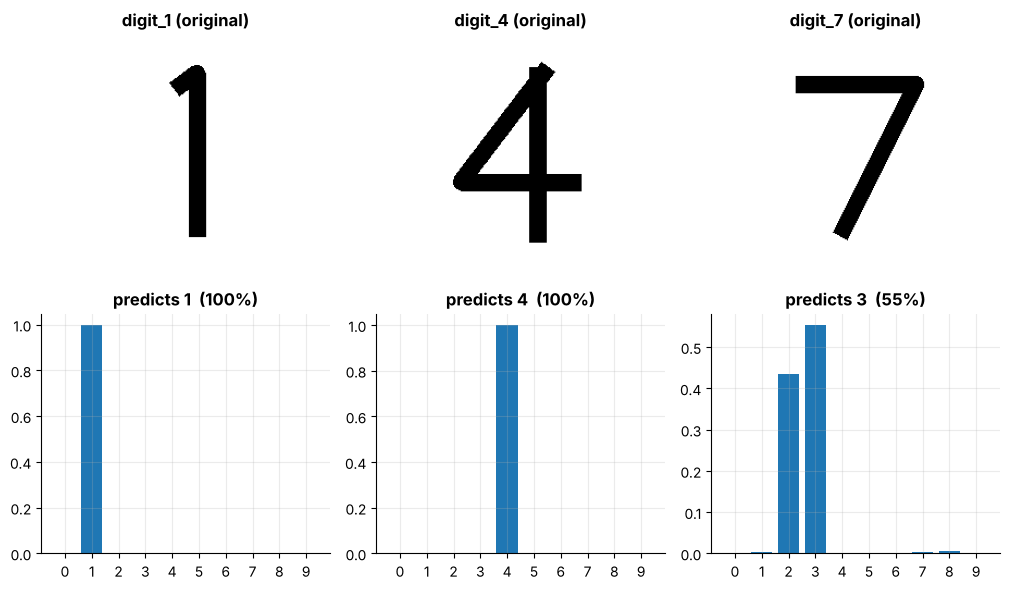

In [12]:
from PIL import Image
from pathlib import Path

def image_to_mnist(path):
    """Turn any photo/scan of a single digit into a 28×28 MNIST-style float array in [0,1]."""
    arr = np.asarray(Image.open(path).convert("L"), dtype=np.float32)
    if arr.mean() > 127:                                   # dark ink on light paper → invert
        arr = 255 - arr
    ys, xs = np.where(arr > 40)                            # find the ink and crop to it
    arr = arr[ys.min():ys.max() + 1, xs.min():xs.max() + 1]
    h, w = arr.shape; s = 20 / max(h, w)                   # scale longest side to 20 px
    small = Image.fromarray(arr.astype(np.uint8)).resize((max(1, round(w * s)), max(1, round(h * s))), Image.LANCZOS)
    canvas = np.zeros((28, 28), np.float32)
    r0, c0 = (28 - small.height) // 2, (28 - small.width) // 2
    canvas[r0:r0 + small.height, c0:c0 + small.width] = np.asarray(small)
    return canvas / 255.0

files = sorted(Path("../data/example_digits").glob("*.png"))
fig, axes = plt.subplots(2, len(files), figsize=(3.4 * len(files), 6))
for k, f in enumerate(files):
    img = image_to_mnist(f)
    p = dl.predict_proba(model, prep(img[None]), device=cpu)[0].numpy()
    axes[0, k].imshow(Image.open(f), cmap="gray"); axes[0, k].set_title(f.stem + " (original)"); axes[0, k].axis("off")
    axes[1, k].bar(range(10), p); axes[1, k].set_xticks(range(10)); axes[1, k].set_title(f"predicts {p.argmax()}  ({p.max():.0%})")
plt.tight_layout(); plt.show()

> 📝 **Note**: The sample images are *drawn from straight line segments*, so they look different from natural handwriting and the model may be unsure: a nice demonstration of **distribution shift** (training data ≠ deployment data). Try your own pen-written digits!

---
## 🔁 11. The same model in Keras (preview of Lesson 15)

You'll learn Keras properly in Lesson 15; here's the same ANN so you can see the family resemblance (not executed in this notebook):

```python
from tensorflow import keras
model = keras.Sequential([
    keras.layers.Input((28, 28)),
    keras.layers.Flatten(),
    keras.layers.Dense(256, activation="relu"),
    keras.layers.Dense(128, activation="relu"),
    keras.layers.Dense(10),                               # logits
])
model.compile(optimizer=keras.optimizers.Adam(1e-3),
              loss=keras.losses.SparseCategoricalCrossentropy(from_logits=True),
              metrics=["accuracy"])
model.fit(x_train, y_train, validation_data=(x_val, y_val), epochs=12, batch_size=128)
```
`compile` chooses the loss/optimiser; `fit` *is* our training loop.

---
## 📝 12. Project report (fill this in!)

Copy this table into your notes and complete it. Professional ML work is *communication* as much as code.

| Item | Your result |
|:--|:--|
| Problem & success criterion | |
| Data (size, split, preprocessing) | 16,000 / 4,000 / 5,000; standardised with train mean/std |
| Baselines (majority, logistic regression) | |
| Final model (architecture, #params, optimiser, LR, epochs, batch) | 784-256-128-10, 235k params, Adam 1e-3, 12 epochs, B=128 |
| Validation accuracy | |
| **Test accuracy (reported once)** | |
| Most confused digit pairs | |
| Robustness findings | accuracy at 3-px shift = |
| Confidence/reject policy | |
| Limitations & next steps | e.g. try a CNN (Lesson 08) |

### 🚀 Stretch goals
1. Beat 98 % with an ANN: tune width/depth/LR/epochs *using the validation set only*.
2. Add `nn.Dropout(0.2)` after each hidden layer (peek at Lesson 14): does the gap between train and validation shrink?
3. **Data augmentation:** train on randomly shifted copies of the training images (±3 px) and re-run the robustness test. How far does the collapse curve flatten?
4. Plot the **learned weights** of the first-layer neurons as 28×28 images (`model[1].weight[i].reshape(28, 28)`). What do they look like?

---
# 🏋️ Practice problems
Work through these in order. Each problem has **hints** (open them one at a time: struggling a little is how learning happens!) and a **self-check cell** that tells you ✅ or ❌. Full solutions live in `../solutions/`.

*Difficulty:* ⭐ warm-up · ⭐⭐ standard · ⭐⭐⭐ challenge

---
### 🧩 Problem 7.1: Per-class accuracy from a confusion matrix  &nbsp; `⭐`

Given a confusion matrix `cm` (rows = true class, columns = predicted), write `per_class_accuracy(cm)` returning each class's **recall**: the diagonal divided by the row sum.

<details><summary>💡 Hint 1</summary>

`np.diag(cm)` gives the correct counts per class.

</details>

<details><summary>💡 Hint 2</summary>

`cm.sum(axis=1)` gives how many true examples each class has.

</details>


In [ ]:
def per_class_accuracy(cm):
    pass

In [ ]:
# ▶ self-check (run after you've written your answer)
cm = np.array([[50, 2, 3], [5, 40, 5], [0, 1, 9]])
r = per_class_accuracy(cm)
dl.check("returns [50/55, 40/50, 9/10]", r is not None and np.allclose(r, [50/55, 0.8, 0.9]))

---
### 🧩 Problem 7.2: Most confidently wrong  &nbsp; `⭐⭐`

Write `most_confident_mistakes(probs, y, k=5)`. `probs` is an `(N, C)` NumPy array of predicted probabilities and `y` the true labels.
Return the **indices of the `k` misclassified examples whose predicted probability was highest**, sorted from most to least confident.

<details><summary>💡 Hint 1</summary>

`pred = probs.argmax(1)`; `wrong = np.where(pred != y)[0]`.

</details>

<details><summary>💡 Hint 2</summary>

Confidence = `probs[wrong, pred[wrong]]`.

</details>

<details><summary>💡 Hint 3</summary>

`np.argsort(-conf)[:k]` sorts descending; map back through `wrong`.

</details>


In [ ]:
def most_confident_mistakes(probs, y, k=5):
    pass

In [ ]:
# ▶ self-check (run after you've written your answer)
probs = np.array([[.9, .1], [.2, .8], [.6, .4], [.05, .95], [.7, .3]])
y = np.array([0, 0, 1, 0, 0])
res = most_confident_mistakes(probs, y, k=2)
dl.check("returns [3, 1] (wrong examples: idx 1 at 0.8, idx 2 at 0.6, idx 3 at 0.95)", res is not None and list(res) == [3, 1])
dl.check("never returns correct predictions", res is not None and all(np.argmax(probs[i]) != y[i] for i in res))

---
### 🧩 Problem 7.3: Translate an image  &nbsp; `⭐⭐`

Implement `shift_images(x, dx, dy=0)`: translate each image in the batch `x` (shape `(N, H, W)`) right by `dx` pixels and down by `dy` pixels (negative = left/up),
filling vacated pixels with **0** (no wrap-around!).

<details><summary>💡 Hint 1</summary>

Start with `out = np.zeros_like(x)` and copy a **slice** of `x` into a shifted slice of `out`.

</details>

<details><summary>💡 Hint 2</summary>

For `dx > 0`: `out[:, :, dx:] = x[:, :, :W-dx]`. For `dx < 0`: `out[:, :, :W+dx] = x[:, :, -dx:]`.

</details>

<details><summary>💡 Hint 3</summary>

Handle `dx == 0` carefully (a `:W-0` slice is fine, but `-0` is not what you want).

</details>


In [ ]:
def shift_images(x, dx, dy=0):
    pass

In [ ]:
# ▶ self-check (run after you've written your answer)
x = np.arange(1, 10, dtype=float).reshape(1, 3, 3)       # [[1 2 3],[4 5 6],[7 8 9]]
r = shift_images(x, 1, 0)
dl.check("shift right by 1", r is not None and np.array_equal(r[0], [[0, 1, 2], [0, 4, 5], [0, 7, 8]]))
dl.check("shift left by 1", np.array_equal(shift_images(x, -1)[0], [[2, 3, 0], [5, 6, 0], [8, 9, 0]]))
dl.check("shift down by 1", np.array_equal(shift_images(x, 0, 1)[0], [[0, 0, 0], [1, 2, 3], [4, 5, 6]]))
dl.check("no shift returns the same image", np.array_equal(shift_images(x, 0)[0], x[0]))

---
### 🧩 Problem 7.4: Reject option: coverage vs accuracy  &nbsp; `⭐⭐`

Write `reject_curve(probs, y, thresholds)` returning a list of `(threshold, coverage, accuracy_on_kept)` tuples, where *coverage* is the fraction of examples with max-probability ≥ threshold
and the accuracy is measured **only on those kept examples** (use `float('nan')` if none are kept).

<details><summary>💡 Hint 1</summary>

`conf = probs.max(1)`, `pred = probs.argmax(1)`.

</details>

<details><summary>💡 Hint 2</summary>

`keep = conf >= t`; coverage = `keep.mean()`; accuracy = `(pred[keep] == y[keep]).mean()` when `keep.any()`.

</details>


In [ ]:
def reject_curve(probs, y, thresholds):
    pass

In [ ]:
# ▶ self-check (run after you've written your answer)
probs = np.array([[.9, .1], [.6, .4], [.55, .45], [.2, .8]]); y = np.array([0, 1, 0, 1])
r = reject_curve(probs, y, [0.5, 0.7, 0.95])
ok = r is not None and len(r) == 3
dl.check("threshold .5 keeps everyone, accuracy 3/4", ok and np.isclose(r[0][1], 1.0) and np.isclose(r[0][2], 0.75))
dl.check("threshold .7 keeps 2 of 4, both right", ok and np.isclose(r[1][1], 0.5) and np.isclose(r[1][2], 1.0))
dl.check("threshold .95 keeps nobody → NaN accuracy", ok and r[2][1] == 0 and np.isnan(r[2][2]))

---
### 🧩 Problem 7.5: Design challenge: a lean, accurate model  &nbsp; `⭐⭐⭐`

Return an `nn.Module` from `my_model()` with **at most 120,000 parameters** that, under our fixed training protocol
(16 000 training images, Adam lr 1e-3, batch 128, **8 epochs**), reaches **≥ 95.5 % validation accuracy**.
The starter is plain logistic regression (≈ 91 %). Improve it! (The self-check runs the protocol for you; about 15 seconds.)

<details><summary>💡 Hint 1</summary>

You need at least one hidden layer with a non-linearity. `nn.Linear(784, 128), nn.ReLU(), nn.Linear(128, 10)` is already ~100k parameters.

</details>

<details><summary>💡 Hint 2</summary>

Parameters: `784·h + h + h·10 + 10`. For h = 128 that's 101,770 ✔️.

</details>

<details><summary>💡 Hint 3</summary>

Two small hidden layers (e.g. 128 and 64) = 109,386 parameters and typically exceeds 96 %.

</details>


In [ ]:
def my_model():
    return nn.Sequential(nn.Flatten(), nn.Linear(784, 10))     # ← improve me! (≤ 120,000 params)

In [ ]:
# ▶ self-check (run after you've written your answer)
import torch
from torch.utils.data import TensorDataset, DataLoader
xa, ya, _, _ = dl.load_mnist()
perm = np.random.default_rng(0).permutation(len(ya)); vi, ti = perm[:4000], perm[4000:]
m_, s_ = xa[ti].mean(), xa[ti].std()
P = lambda a: torch.tensor((a - m_) / s_, dtype=torch.float32)
tdl = DataLoader(TensorDataset(P(xa[ti]), torch.tensor(ya[ti])), batch_size=128, shuffle=True)
vdl = DataLoader(TensorDataset(P(xa[vi]), torch.tensor(ya[vi])), batch_size=1000)
dl.set_seed(0)
net = my_model()
n = dl.count_params(net)
dl.check(f"≤ 120,000 parameters (yours: {n:,})", n <= 120_000)
h = dl.fit(net, tdl, vdl, torch.nn.CrossEntropyLoss(), torch.optim.Adam(net.parameters(), lr=1e-3), epochs=8, device=torch.device("cpu"), verbose=False)
dl.check(f"validation accuracy ≥ 95.5% (yours: {h['val_acc'][-1]:.2%})", h["val_acc"][-1] >= 0.955, "add a hidden layer with ReLU")

---
## 🏁 Key takeaways
- ✅ A project follows a **workflow**: frame → explore → split → baseline → model → evaluate → analyse errors → report.
- ✅ Keep the **test set sacred**: use validation for every decision; compute normalisation statistics on training data only.
- ✅ **Baselines** (majority class, logistic regression) tell you what a number like 97 % is actually worth.
- ✅ **Error analysis** (confusion matrix, per-class recall, confident mistakes, looking at the images!) is where insight comes from.
- ✅ **Confidence + a reject option** lets a system hand uncertain cases to a human.
- ✅ A fully-connected ANN is **not translation invariant**: shifting digits breaks it. That's the reason CNNs exist.

---
## 🧠 Check your understanding
Try to answer *out loud* before you open the answer. If you can explain it to a friend, you own it.
**Q1.** Why must the test set be used only once?

<details><summary>Answer</summary>

Every time you look at test results and adjust something, information about the test set leaks into your choices. Reuse makes the final score an optimistic, over-fitted estimate.

</details>

**Q2.** Your model has 97 % accuracy; the majority-class baseline has 11 %. A colleague's dataset has 97 % healthy plants and the baseline gets 97 %. What does that teach?

<details><summary>Answer</summary>

Accuracy is only meaningful relative to the baseline and class balance. With imbalanced classes you need recall/precision/F1 per class, not just accuracy.

</details>

**Q3.** The confusion matrix shows many 4→9 errors. List three possible responses.

<details><summary>Answer</summary>

Collect/augment more 4 and 9 examples; use a model that sees spatial structure (CNN); inspect labels for noise; add a reject option for 4/9 ambiguity.

</details>

**Q4.** Why standardise pixel values using training-set statistics only?

<details><summary>Answer</summary>

To simulate deployment: at test time you don't know the new data's statistics. Using them would leak future information into preprocessing.

</details>

---
## 📚 Go deeper (optional)
- LeCun, Bottou, Bengio & Haffner (1998): *Gradient-based learning applied to document recognition* (the original MNIST/LeNet paper)
- Google ML Crash Course: *Classification: precision, recall and accuracy*
- Andrew Ng: *Machine Learning Yearning* (free), chapters on error analysis

---
⬅️ Previous: [06 · Optimizers, Learning Rates, Epochs & Batch Sizes](06_optimizers_lr_epochs_batches.ipynb) &nbsp;|&nbsp; Next: [08 · Convolutional Neural Networks](08_convolutional_networks.ipynb) ➡️